In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/aiqanhussain/starbucksaq/starbucks.csv


Found CSV: /kaggle/input/datasets/aiqanhussain/starbucksaq/starbucks.csv

--- Dataset Overview ---
Shape: 242 rows, 18 columns



,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0%,0%,0%,0%,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0%,0%,0%,0%,260
2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,0%,0%,330
3,Coffee,Brewed Coffee,Venti,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,2%,0%,410
4,Classic Espresso Drinks,Caffè Latte,Short Nonfat Milk,70,0.1,0.1,0.0,5,75,10,0,9,6.0,10%,0%,20%,0%,75



--- Data Types & Missing Values ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 242 entries, 0 to 241
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Beverage_category          242 non-null    object 
 1   Beverage                   242 non-null    object 
 2   Beverage_prep              242 non-null    object 
 3   Calories                   242 non-null    int64  
 4    Total Fat (g)             242 non-null    object 
 5   Trans Fat (g)              242 non-null    float64
 6   Saturated Fat (g)          242 non-null    float64
 7    Sodium (mg)               242 non-null    int64  
 8    Total Carbohydrates (g)   242 non-null    int64  
 9   Cholesterol (mg)           242 non-null    int64  
 10   Dietary Fibre (g)         242 non-null    int64  
 11   Sugars (g)                242 non-null    int64  
 12   Protein (g)               242 non-null    float64
 13  Vitamin A (% 

,count,mean,std,min,25%,50%,75%,max
Calories,242.0,193.871901,102.863303,0.0,120.0,185.0,260.00,510.0
Trans Fat (g),242.0,1.307025,1.640259,0.0,0.1,0.5,2.00,9.0
Saturated Fat (g),242.0,0.037603,0.071377,0.0,0.0,0.0,0.10,0.3
Sodium (mg),242.0,6.363636,8.630257,0.0,0.0,5.0,10.00,40.0
Total Carbohydrates (g),242.0,128.884298,82.303223,0.0,70.0,125.0,170.00,340.0
Cholesterol (mg),242.0,35.991736,20.795186,0.0,21.0,34.0,50.75,90.0
Dietary Fibre (g),242.0,0.805785,1.445944,0.0,0.0,0.0,1.00,8.0
Sugars (g),242.0,32.962810,19.730199,0.0,18.0,32.0,43.75,84.0
Protein (g),242.0,6.978512,4.871659,0.0,3.0,6.0,10.00,20.0



--- Categorical Summary ---


,count,unique,top,freq
Beverage_category,242,9,Classic Espresso Drinks,58
Beverage,242,33,Caffè Latte,12
Beverage_prep,242,13,Soymilk,66
Total Fat (g),242,24,0.1,34
Vitamin A (% DV),242,11,10%,43
Vitamin C (% DV),242,10,0%,188
Calcium (% DV),242,14,10%,51
Iron (% DV),242,18,0%,99
Caffeine (mg),241,36,75,37


/tmp/ipykernel_16/516536607.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing.index, y=missing.values, palette="viridis")


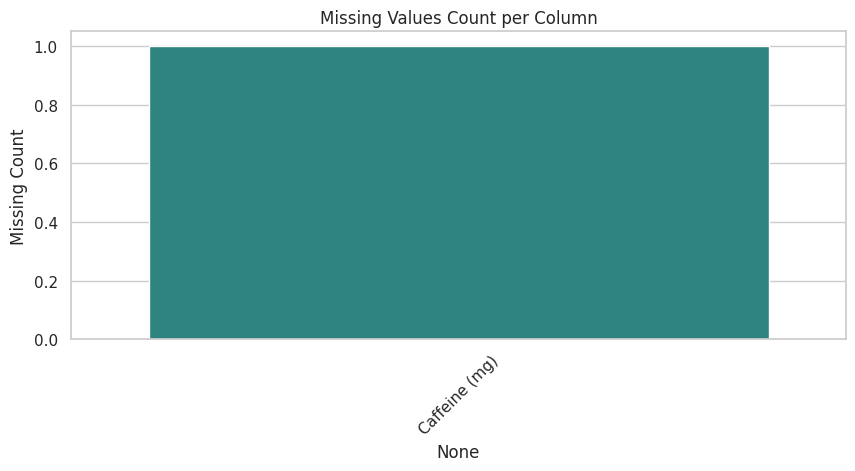

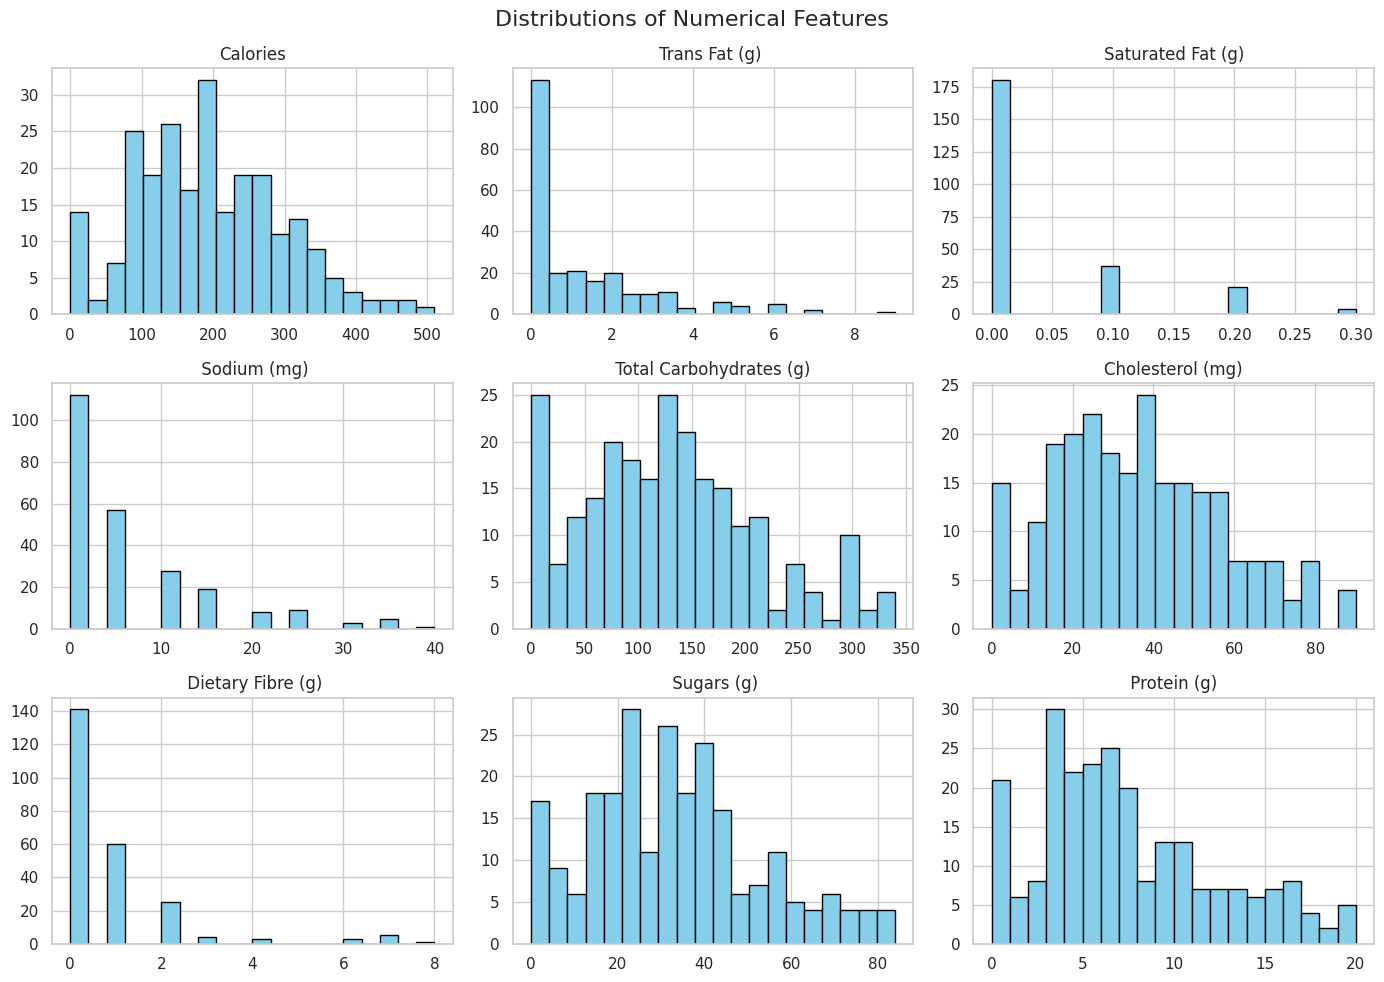

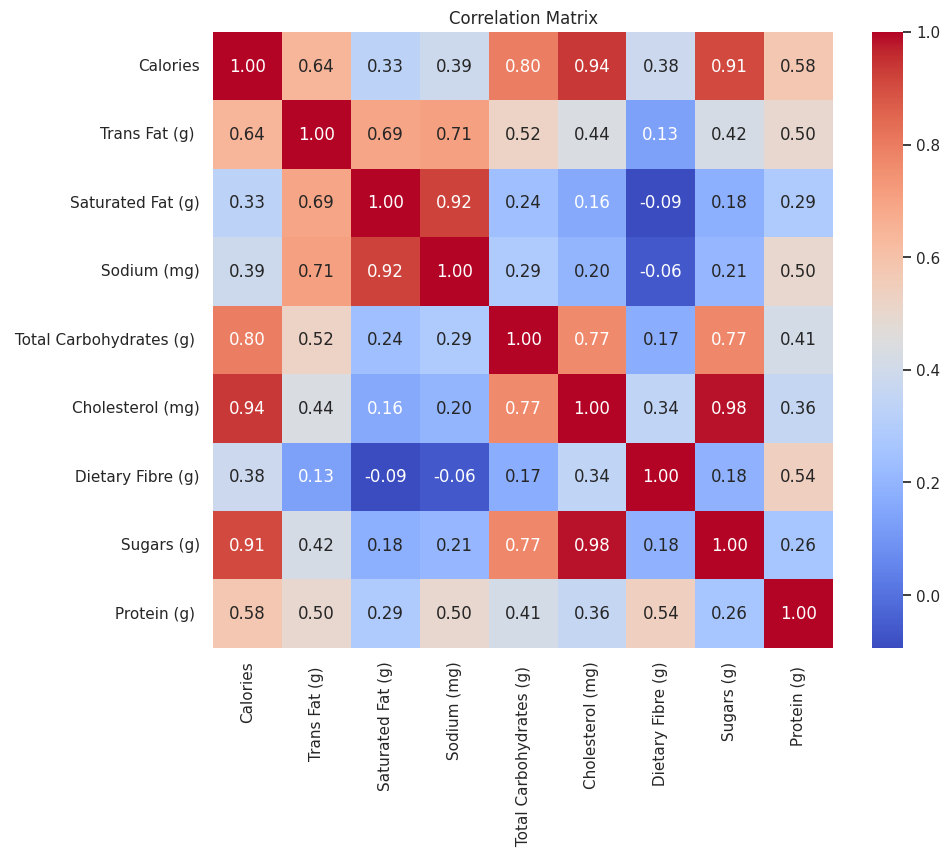

In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visualization styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# ---------------------------------------------------------
# 1. Locate and Load Dataset
# ---------------------------------------------------------
# Locate file path using Kaggle's directory walk
data_path = None
for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        if filename.endswith(".csv"):
            data_path = os.path.join(dirname, filename)
            print(f"Found CSV: {data_path}")
            break

if data_path:
    df = pd.read_csv(data_path)
    print("\n--- Dataset Overview ---")
    print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")

    # Display basic info
    display(df.head())
    print("\n--- Data Types & Missing Values ---")
    print(df.info())

    # ---------------------------------------------------------
    # 2. Summary Statistics
    # ---------------------------------------------------------
    print("\n--- Numerical Summary ---")
    display(df.describe().T)

    print("\n--- Categorical Summary ---")
    display(df.describe(include=["object", "category"]).T)

    # ---------------------------------------------------------
    # 3. Missing Data Analysis
    # ---------------------------------------------------------
    missing = df.isnull().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    if not missing.empty:
        plt.figure(figsize=(10, 4))
        sns.barplot(x=missing.index, y=missing.values, palette="viridis")
        plt.xticks(rotation=45)
        plt.title("Missing Values Count per Column")
        plt.ylabel("Missing Count")
        plt.show()
    else:
        print("\nNo missing values detected.")

    # ---------------------------------------------------------
    # 4. Numerical Distributions
    # ---------------------------------------------------------
    num_cols = df.select_dtypes(include=[np.number]).columns
    if len(num_cols) > 0:
        df[num_cols].hist(bins=20, figsize=(14, 10), color="skyblue", edgecolor="black")
        plt.suptitle("Distributions of Numerical Features", fontsize=16)
        plt.tight_layout()
        plt.show()

    # ---------------------------------------------------------
    # 5. Correlation Heatmap
    # ---------------------------------------------------------
    if len(num_cols) > 1:
        plt.figure(figsize=(10, 8))
        corr = df[num_cols].corr()
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
        plt.title("Correlation Matrix")
        plt.show()

else:
    print("No CSV file found in /kaggle/input.")
    

In [3]:
import pandas as pd

# Load your dataset (the script from the first image handles finding the path automatically)
# Replace with your actual file path if needed, or use the loop method:
df = pd.read_csv(data_path)

# Print all column names
print("Available columns in your dataset:")
print(df.columns.tolist())


Available columns in your dataset:
['Beverage_category', 'Beverage', 'Beverage_prep', 'Calories', ' Total Fat (g)', 'Trans Fat (g) ', 'Saturated Fat (g)', ' Sodium (mg)', ' Total Carbohydrates (g) ', 'Cholesterol (mg)', ' Dietary Fibre (g)', ' Sugars (g)', ' Protein (g) ', 'Vitamin A (% DV) ', 'Vitamin C (% DV)', ' Calcium (% DV) ', 'Iron (% DV) ', 'Caffeine (mg)']


Loading dataset from: /kaggle/input/datasets/aiqanhussain/starbucksaq/starbucks.csv

===== FIRST 5 ROWS =====
         Beverage_category       Beverage      Beverage_prep  Calories  \
0                   Coffee  Brewed Coffee              Short         3   
1                   Coffee  Brewed Coffee               Tall         4   
2                   Coffee  Brewed Coffee             Grande         5   
3                   Coffee  Brewed Coffee              Venti         5   
4  Classic Espresso Drinks    Caffè Latte  Short Nonfat Milk        70   

   Total Fat (g)  Trans Fat (g)   Saturated Fat (g)   Sodium (mg)  \
0            0.1             0.0                0.0             0   
1            0.1             0.0                0.0             0   
2            0.1             0.0                0.0             0   
3            0.1             0.0                0.0             0   
4            0.1             0.1                0.0             5   

    Total Carbohydrates (g)   

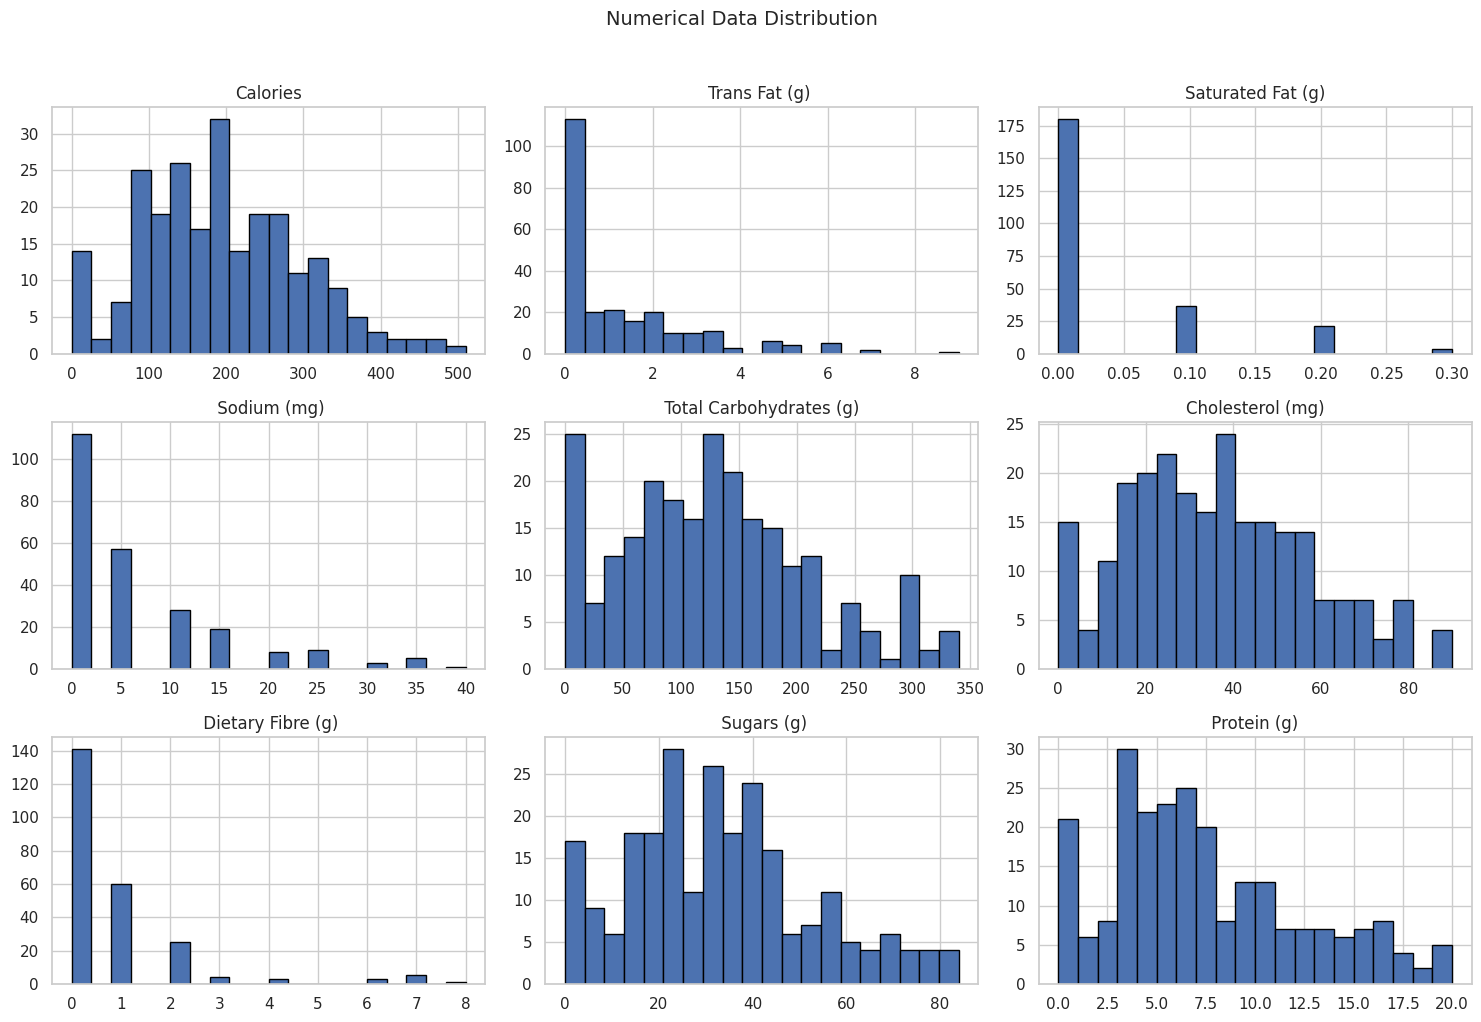

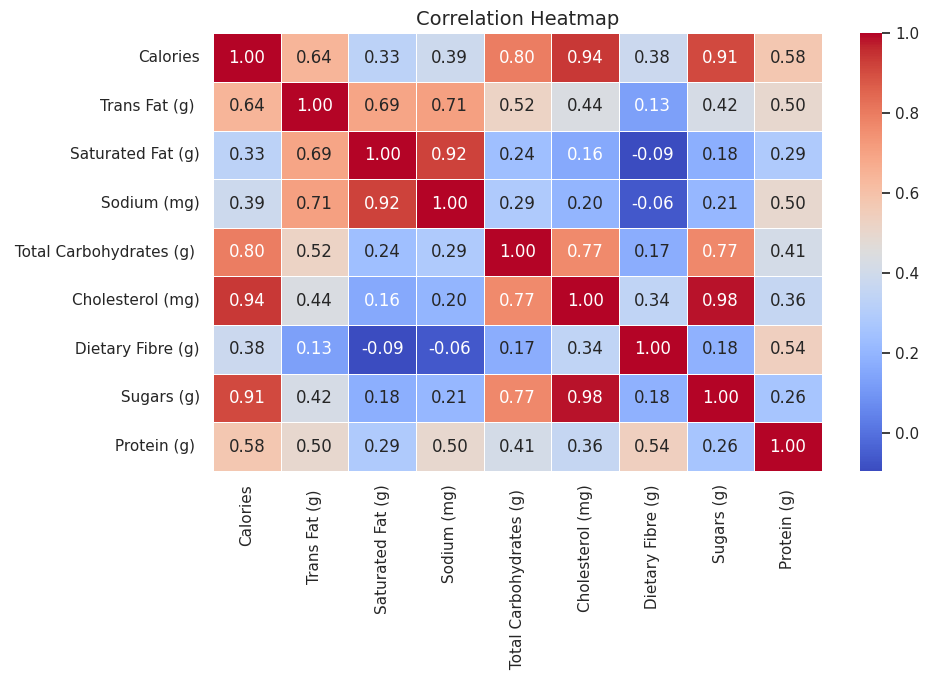


===== CATEGORICAL COLUMNS =====
['Beverage_category', 'Beverage', 'Beverage_prep', ' Total Fat (g)', 'Vitamin A (% DV) ', 'Vitamin C (% DV)', ' Calcium (% DV) ', 'Iron (% DV) ', 'Caffeine (mg)']


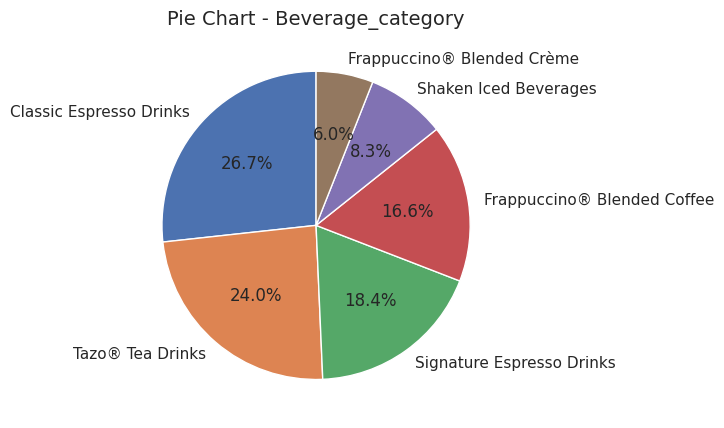

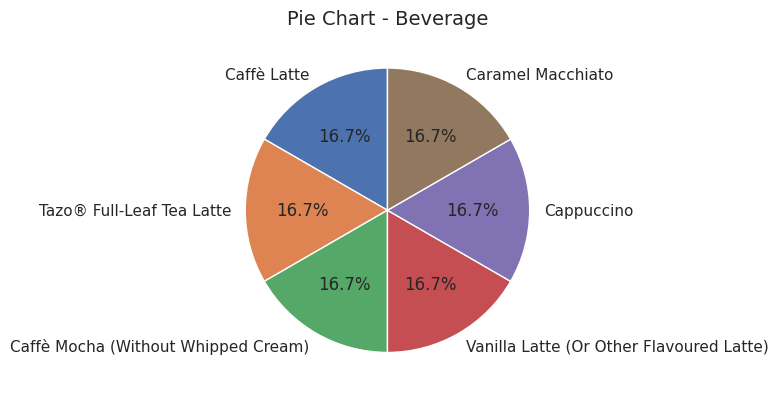

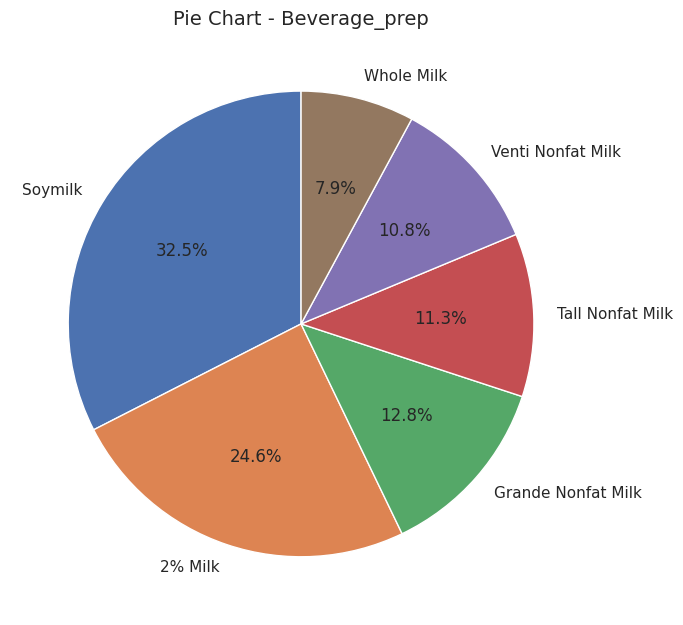

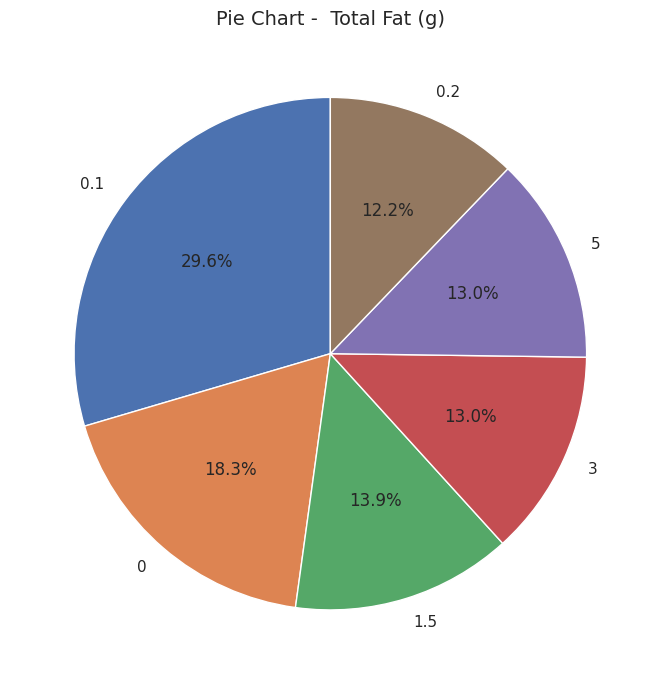

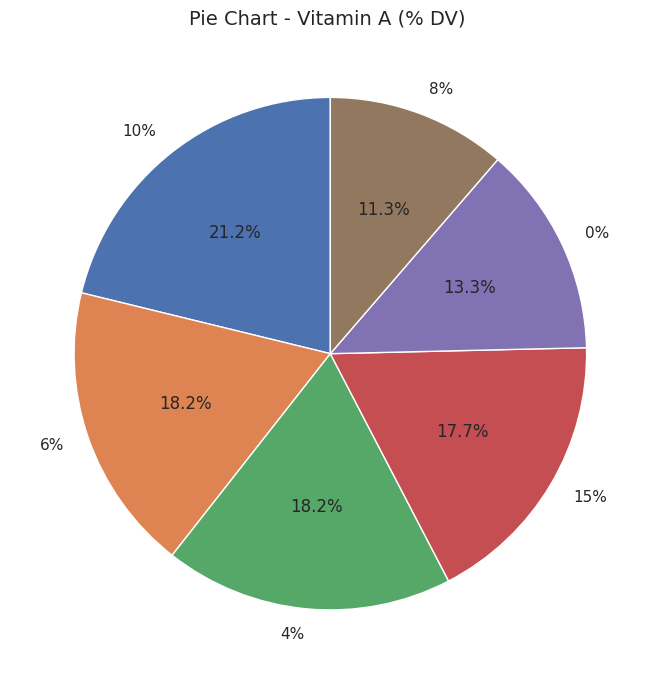

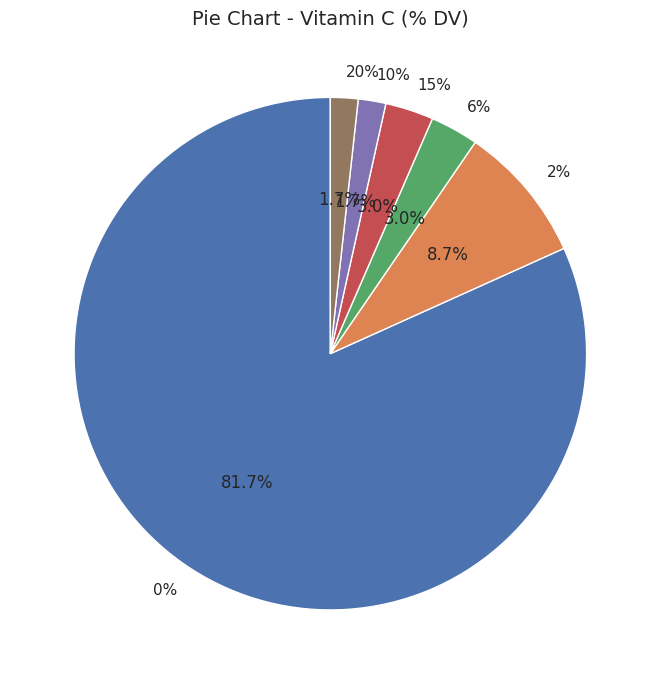

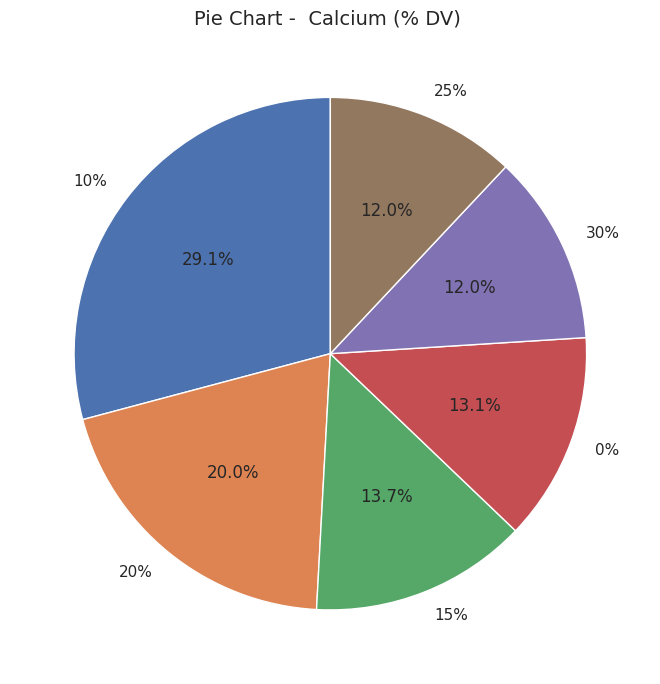

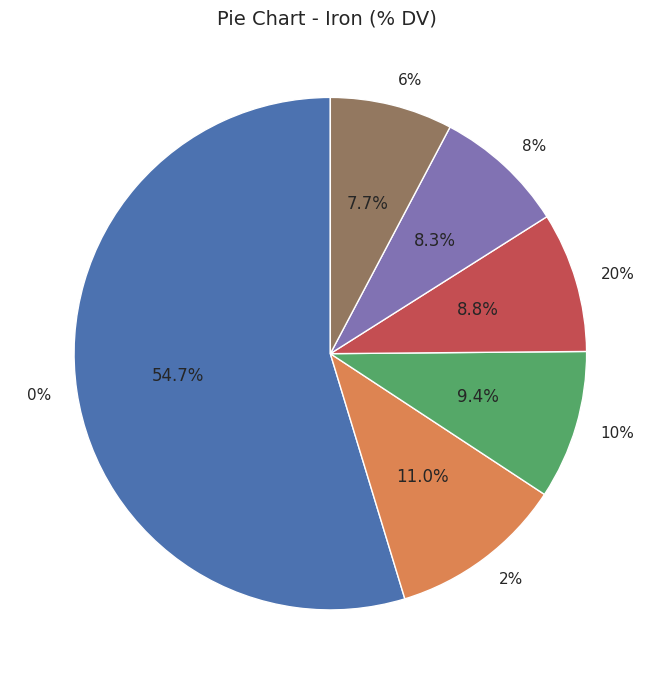

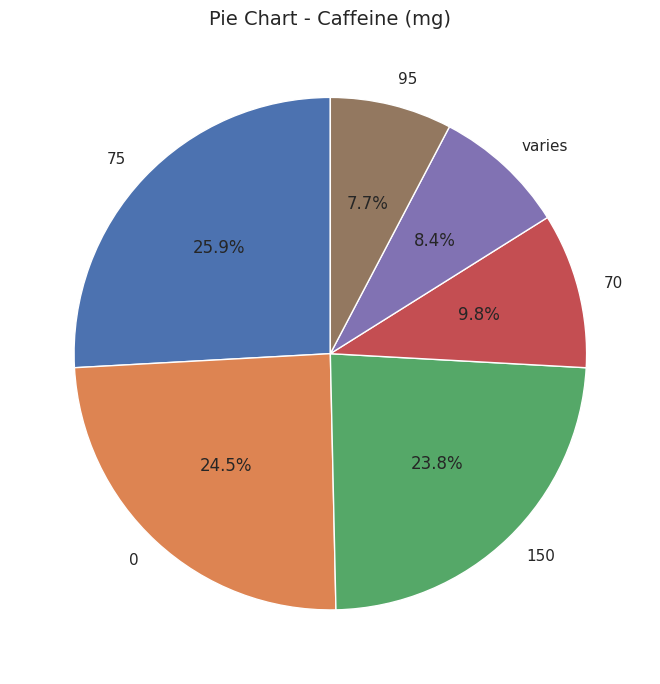

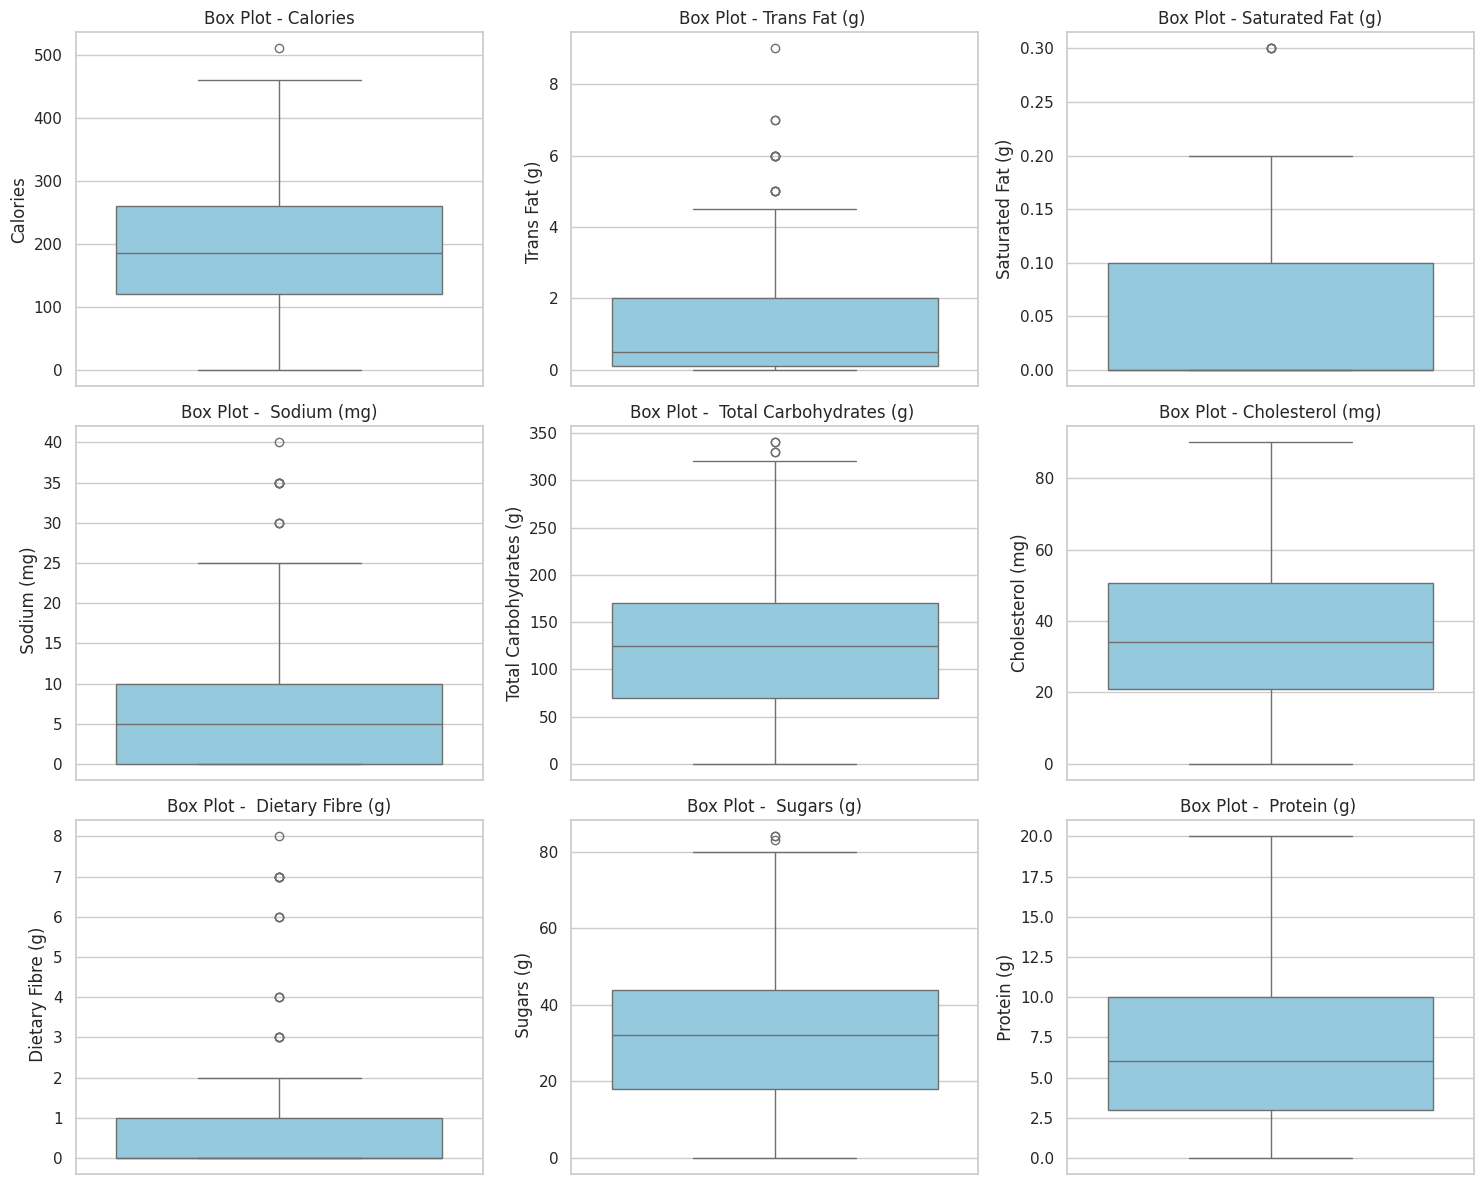


         EDA COMPLETED
Total Rows: 242
Total Columns: 18
Missing Values: 1
Duplicate Rows: 0
Numerical Columns: 9
Categorical Columns: 9


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Automatically locate the CSV file in Kaggle's input directory
input_dir = "/kaggle/input"
csv_file = None

for root, dirs, files in os.walk(input_dir):
    for file in files:
        if file.endswith(".csv"):
            csv_file = os.path.join(root, file)
            break
    if csv_file:
        break

if not csv_file:
    raise FileNotFoundError("No CSV file found in /kaggle/input/. Please check if the dataset was added.")

print(f"Loading dataset from: {csv_file}")
df = pd.read_csv(csv_file)

# ==============================
# BASIC EDA
# ==============================

print("\n===== FIRST 5 ROWS =====")
print(df.head())

print("\n===== SHAPE =====")
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")

print("\n===== COLUMN NAMES =====")
print(df.columns.tolist())

print("\n===== DATA TYPES =====")
print(df.dtypes)

print("\n===== MISSING VALUES =====")
print(df.isnull().sum())

print("\n===== DUPLICATE ROWS =====")
print(df.duplicated().sum())

print("\n===== STATISTICAL SUMMARY =====")
print(df.describe(include="all"))

# ==============================
# NUMERICAL COLUMNS & HISTOGRAMS
# ==============================

numeric_cols = df.select_dtypes(include="number").columns
print("\n===== NUMERICAL COLUMNS =====")
print(list(numeric_cols))

if len(numeric_cols) > 0:
    df[numeric_cols].hist(figsize=(15, 10), bins=20, edgecolor="black")
    plt.suptitle("Numerical Data Distribution", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

# ==============================
# CORRELATION HEATMAP
# ==============================

if len(numeric_cols) > 1:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        df[numeric_cols].corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )
    plt.title("Correlation Heatmap", fontsize=14)
    plt.tight_layout()
    plt.show()

# ==============================
# PIE GRAPHS (Categorical Columns)
# ==============================

categorical_cols = df.select_dtypes(exclude="number").columns
print("\n===== CATEGORICAL COLUMNS =====")
print(list(categorical_cols))

for col in categorical_cols:
    # Limited to top 6 categories to prevent overcrowded pie charts
    counts = df[col].value_counts().head(6)

    if len(counts) > 1:
        plt.figure(figsize=(7, 7))
        plt.pie(
            counts.values,
            labels=counts.index,
            autopct="%1.1f%%",
            startangle=90,
            wedgeprops={"edgecolor": "white"}
        )
        plt.title(f"Pie Chart - {col}", fontsize=14)
        plt.tight_layout()
        plt.show()

# ==============================
# BOX PLOTS (Grouped in Subplots)
# ==============================

if len(numeric_cols) > 0:
    n_cols = min(3, len(numeric_cols))
    n_rows = (len(numeric_cols) + n_cols - 1) // n_cols

    plt.figure(figsize=(15, 4 * n_rows))
    for i, col in enumerate(numeric_cols):
        plt.subplot(n_rows, n_cols, i + 1)
        sns.boxplot(y=df[col], color="skyblue")
        plt.title(f"Box Plot - {col}")
        plt.tight_layout()
    plt.show()

# ==============================
# FINAL SUMMARY
# ==============================

print("\n" + "=" * 30)
print("         EDA COMPLETED")
print("=" * 30)
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print(f"Missing Values: {df.isnull().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")
print(f"Numerical Columns: {len(numeric_cols)}")
print(f"Categorical Columns: {len(categorical_cols)}")

Model Accuracy: 0.7143

Classification Report:
                                   precision    recall  f1-score   support

          Classic Espresso Drinks       0.91      0.71      0.80        14
      Frappuccino® Blended Coffee       0.80      1.00      0.89         8
       Frappuccino® Blended Crème       1.00      0.25      0.40         4
Frappuccino® Light Blended Coffee       1.00      1.00      1.00         1
            Shaken Iced Beverages       1.00      0.80      0.89         5
        Signature Espresso Drinks       1.00      0.14      0.25         7
                 Tazo® Tea Drinks       0.48      1.00      0.65        10

                         accuracy                           0.71        49
                        macro avg       0.88      0.70      0.70        49
                     weighted avg       0.83      0.71      0.68        49



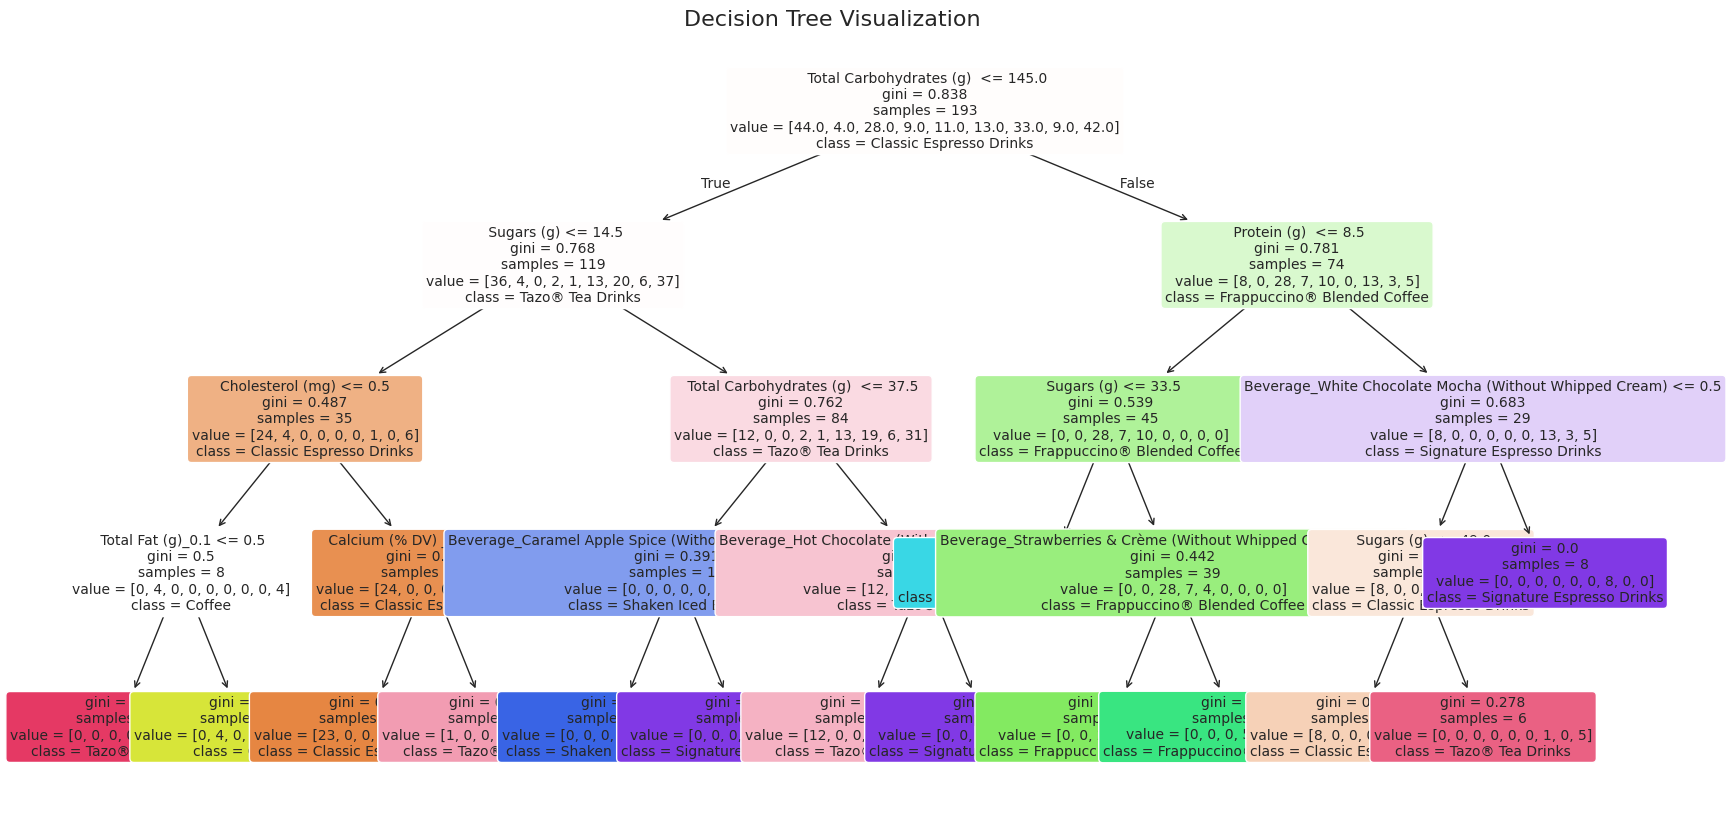

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

# 1. Automatically locate the CSV file in Kaggle's input directory
input_dir = "/kaggle/input"
csv_file = None

for root, dirs, files in os.walk(input_dir):
    for file in files:
        if file.endswith(".csv"):
            csv_file = os.path.join(root, file)
            break
    if csv_file:
        break

if not csv_file:
    raise FileNotFoundError("No CSV file found in /kaggle/input/. Please check if the dataset was added.")

df = pd.read_csv(csv_file)

# ==============================
# DECISION TREE MODEL
# ==============================

# Replace 'your_target_column' with the actual column you want to predict
target_col = "Beverage_category" 

if target_col in df.columns:
    # Drop rows where target is missing
    df_model = df.dropna(subset=[target_col])

    X = df_model.drop(columns=[target_col])
    y = df_model[target_col]

    # Handle categorical variables and missing values
    X = pd.get_dummies(X, drop_first=True)
    X = X.fillna(X.mean(numeric_only=True))

    # Split dataset (80% train, 20% test)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Train Decision Tree Classifier
    clf = DecisionTreeClassifier(max_depth=4, random_state=42)
    clf.fit(X_train, y_train)

    # Predictions & Evaluation
    y_pred = clf.predict(X_test)
    print(f"Model Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    # Plot the Decision Tree
    plt.figure(figsize=(20, 10))
    plot_tree(
        clf, 
        feature_names=X.columns, 
        class_names=[str(c) for c in clf.classes_], 
        filled=True, 
        rounded=True,
        fontsize=10
    )
    plt.title("Decision Tree Visualization", fontsize=16)
    plt.show()
else:
    print(f"Target column '{target_col}' not found. Please update the 'target_col' variable.")